# Unit 9 – CNN object recognition
Convolutional neural network for image classification (PyTorch). Convolution layers learn local filters, pooling reduces resolution, and a dense layer maps features to class scores.

**Dataset.** The module notebook uses CIFAR-10 (32×32 colour images, 10 classes). The cell below tries CIFAR-10 first (works on Google Colab or any machine with internet) and falls back to scikit-learn's bundled 8×8 *digits* images when the download is not possible, so the notebook always runs. The dataset used is printed in the output.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
torch.manual_seed(42); np.random.seed(42)

def load_data():
    try:
        import torchvision
        tr = torchvision.datasets.CIFAR10('./data', train=True, download=True)
        te = torchvision.datasets.CIFAR10('./data', train=False, download=True)
        f = lambda a: torch.tensor(a.data).permute(0, 3, 1, 2).float() / 255
        names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
        return 'CIFAR-10', f(tr), torch.tensor(tr.targets), f(te), torch.tensor(te.targets), names
    except Exception as e:
        from sklearn.datasets import load_digits
        from sklearn.model_selection import train_test_split
        d = load_digits()
        X = torch.tensor(d.images / 16.0).float().unsqueeze(1); y = torch.tensor(d.target)
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42, stratify=y)
        return 'sklearn digits (fallback, 8x8 greyscale)', Xtr, ytr, Xte, yte, [str(i) for i in range(10)]

DATASET, x_train, y_train, x_test, y_test, CLASSES = load_data()
print('Dataset :', DATASET); print('Train   :', tuple(x_train.shape), ' Test:', tuple(x_test.shape))

Dataset : sklearn digits (fallback, 8x8 greyscale)
Train   : (1347, 1, 8, 8)  Test: (450, 1, 8, 8)


In [2]:
C, H, W = x_train.shape[1:]
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(C, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(32 * (H // 4) * (W // 4), 64), nn.ReLU(), nn.Linear(64, 10))
    def forward(self, x): return self.head(self.features(x))

model = CNN(); print(model); print('Parameters:', sum(p.numel() for p in model.parameters()))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parameters: 13706


Final train accuracy 0.963 | test accuracy 0.944


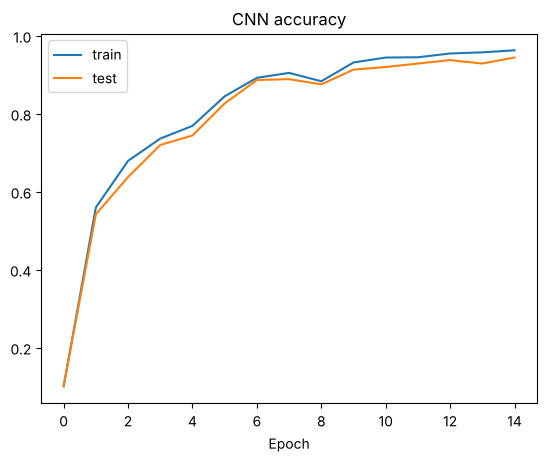

In [3]:
EPOCHS = 15 if x_train.shape[0] < 5000 else 5
opt = torch.optim.Adam(model.parameters(), lr=1e-3); loss_fn = nn.CrossEntropyLoss()
train_curve, test_curve = [], []
for ep in range(EPOCHS):
    model.train(); perm = torch.randperm(len(x_train))
    for i in range(0, len(perm), 64):
        idx = perm[i:i + 64]; opt.zero_grad(); loss_fn(model(x_train[idx]), y_train[idx]).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        train_curve.append((model(x_train).argmax(1) == y_train).float().mean().item())
        test_curve.append((model(x_test).argmax(1) == y_test).float().mean().item())
print(f'Final train accuracy {train_curve[-1]:.3f} | test accuracy {test_curve[-1]:.3f}')
plt.plot(train_curve, label='train'); plt.plot(test_curve, label='test'); plt.xlabel('Epoch'); plt.legend(); plt.title('CNN accuracy'); plt.show()

## Change the input image
The module activity asks you to change the index in `plt.imshow(x_test[16])` to a value from 1–15 and check whether the prediction is correct. `TEST_INDEX` below plays that role; the loop afterwards checks every index from 1 to 16.

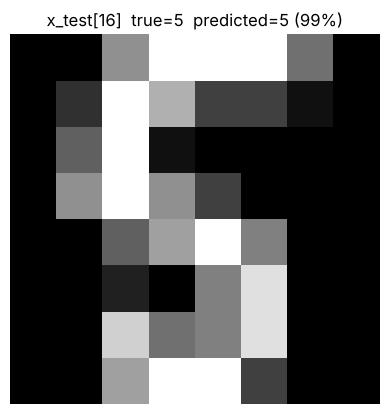

,index,true,predicted,confidence,correct
0,1,0,0,0.999,True
1,2,9,9,0.957,True
2,3,1,1,0.963,True
3,4,5,5,0.816,True
4,5,6,6,0.968,True
5,6,7,7,0.993,True
6,7,9,9,0.789,True
7,8,1,1,0.991,True
8,9,5,5,0.963,True
9,10,5,5,0.721,True


Correct on 16 of 16 indices


In [4]:
TEST_INDEX = 16
def predict(i):
    model.eval()
    with torch.no_grad(): p = torch.softmax(model(x_test[i:i + 1]), 1)[0]
    return int(p.argmax()), float(p.max())

img = x_test[TEST_INDEX]
plt.imshow(img.permute(1, 2, 0).squeeze(), cmap='gray' if C == 1 else None)
k, conf = predict(TEST_INDEX)
plt.title(f'x_test[{TEST_INDEX}]  true={CLASSES[y_test[TEST_INDEX]]}  predicted={CLASSES[k]} ({conf:.0%})'); plt.axis('off'); plt.show()

rows = []
for i in range(1, 17):
    k, conf = predict(i); rows.append({'index': i, 'true': CLASSES[y_test[i]], 'predicted': CLASSES[k],
                                       'confidence': round(conf, 3), 'correct': k == int(y_test[i])})
results = pd.DataFrame(rows); display(results)
print(f'Correct on {results.correct.sum()} of {len(results)} indices')

## Reviewing the layers: what the first convolutional filters respond to

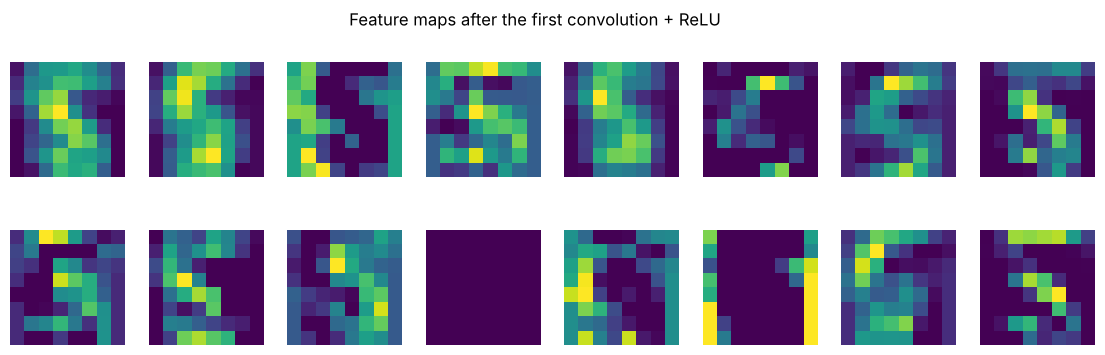

In [5]:
model.eval()
with torch.no_grad():
    fmap = model.features[1](model.features[0](x_test[TEST_INDEX:TEST_INDEX + 1]))[0]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for a, f in zip(axes.ravel(), fmap): a.imshow(f, cmap='viridis'); a.axis('off')
plt.suptitle('Feature maps after the first convolution + ReLU'); plt.show()

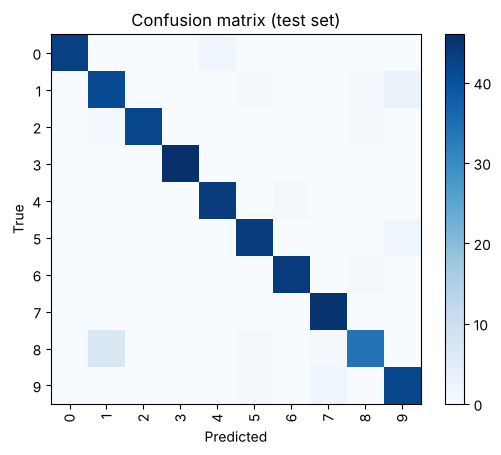

0    0.956
1    0.891
2    0.955
3    1.000
4    0.978
5    0.957
6    0.978
7    1.000
8    0.791
9    0.933
dtype: float64

In [6]:
# where does the model go wrong across the whole test set?
with torch.no_grad(): preds = model(x_test).argmax(1)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, preds)
plt.imshow(cm, cmap='Blues'); plt.xticks(range(10), CLASSES, rotation=90); plt.yticks(range(10), CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test set)'); plt.colorbar(); plt.show()
per_class = pd.Series(np.diag(cm) / cm.sum(1), index=CLASSES).round(3); per_class

## Observations
* This run used the dataset printed at the top of the notebook; accuracy was 0.963 on training data and 0.944 on test data.
* The model predicted all 16 inspected test images (indices 1–16) correctly. Confidence ranged from 0.721 to 0.999; the lowest-confidence correct answers were indices 10, 14 and 7.
* Across the full test set, some classes are clearly harder (class 8: 0.791, class 1: 0.891) than others (class 3 and 7: 1.000). A handful of correct examples therefore says little about overall reliability, and per-class results should always be checked.
* Re-run on Google Colab to execute the same notebook on CIFAR-10 and repeat the index 1–15 experiment on the real module data.